# 5. Classification: who will subscribe to a term deposit?

The business question: given what the bank knows about a client before calling, how likely are they to subscribe, and who is worth calling?

Plan:
1. Drop `duration` (it leaks the outcome, see notebook 1).
2. Hold out 20% as a test set, stratified on the target.
3. Compare logistic regression, random forest and LightGBM with stratified 5-fold cross-validation on the other 80%.
4. Look at calibration, then pick a call threshold from a stated cost assumption.
5. Check which features the best model relies on.

In [1]:
import json
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from lightgbm import LGBMClassifier
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

from src import SEED
from src.data import load_bank
from src.modeling import best_threshold, cost_curve, expected_cost
from src.plotting import INK_2, PALETTE, save, set_style

set_style()
np.random.seed(SEED)
RESULTS = Path.cwd().parent / "results"
RESULTS.mkdir(exist_ok=True)

bank = load_bank(drop_duration=True)
assert "duration" not in bank.columns

## Features

`pdays` is "days since last contact", and is missing for the 96% of clients who were never contacted. I keep the `previously_contacted` flag plus `previous` and `poutcome`, which carry the same history without a mostly empty column.

In [2]:
y = bank["subscribed"]
X = bank.drop(columns=["subscribed", "pdays"])
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print("categorical:", cat_cols)
print("numeric:", num_cols)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"train {len(X_train):,} rows, positive rate {y_train.mean():.4f}")
print(f"test  {len(X_test):,} rows, positive rate {y_test.mean():.4f}")

categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
numeric: ['age', 'campaign', 'previous', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed', 'previously_contacted']
train 32,950 rows, positive rate 0.1127
test  8,238 rows, positive rate 0.1126


A note on the split. The rows are in time order (May 2008 to November 2010), and the economy changed a lot over that period. A random stratified split answers "how well does this rank clients from the same period". A time split would answer "how well does it work next quarter", which is harder. I use the stratified version for model comparison because it is the usual setup for this dataset. At the end I run one time-ordered check to see how much that choice flatters the numbers.

## Pipelines

Every preprocessing step lives inside a scikit-learn `Pipeline`, so it is fitted only on the training folds during cross-validation. Scaling or encoding on the full data first is a quiet form of leakage.

- Logistic regression gets one-hot encoding and scaling.
- Trees get ordinal codes. They do not need one-hot or scaling.

In [3]:
pre_linear = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
])
pre_tree = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols),
    ("num", "passthrough", num_cols),
], verbose_feature_names_out=False)

models = {
    "logistic": Pipeline([("pre", pre_linear), ("clf", LogisticRegression(max_iter=2000, C=1.0))]),
    "logistic (balanced)": Pipeline([("pre", pre_linear), ("clf", LogisticRegression(max_iter=2000, C=1.0, class_weight="balanced"))]),
    "random forest": Pipeline([("pre", pre_tree), ("clf", RandomForestClassifier(
        n_estimators=400, min_samples_leaf=10, max_features="sqrt", n_jobs=4, random_state=SEED))]),
    "lightgbm": Pipeline([("pre", pre_tree), ("clf", LGBMClassifier(
        n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=50,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1, n_jobs=4))]),
}

## Stratified 5-fold cross-validation

Stratified folds keep the 11% positive rate the same in every fold, so the scores are comparable. I track:

- **ROC-AUC:** chance a random subscriber is ranked above a random non-subscriber.
- **PR-AUC (average precision):** precision across recall levels. With rare positives this is the more honest metric, since the baseline is the positive rate (about 0.11), not 0.5.
- **Brier score:** mean squared error of the probabilities. Lower is better and it punishes bad calibration.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "brier": "neg_brier_score"}
cv_rows = []
for name, model in models.items():
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_rows.append({
        "model": name,
        "roc_auc": s["test_roc_auc"].mean(), "roc_auc_sd": s["test_roc_auc"].std(),
        "pr_auc": s["test_pr_auc"].mean(), "pr_auc_sd": s["test_pr_auc"].std(),
        "brier": -s["test_brier"].mean(),
    })
cv_df = pd.DataFrame(cv_rows).set_index("model")
cv_df

,roc_auc,roc_auc_sd,pr_auc,pr_auc_sd,brier
model,,,,,
logistic,0.788901,0.006652,0.449569,0.010183,0.078886
logistic (balanced),0.789611,0.005424,0.443892,0.008020,0.165119
random forest,0.791812,0.003617,0.468896,0.010121,0.077206
lightgbm,0.794807,0.003652,0.469342,0.012638,0.077262


The tree models edge out logistic regression, but not by much: CV ROC-AUC 0.795 for LightGBM against 0.789 for logistic, and PR-AUC 0.469 against 0.450. Fold-to-fold standard deviations are 0.004 to 0.013, so random forest and LightGBM are effectively tied. Most of the signal sits in a few strong columns, which a linear model can use almost as well.

## Handling imbalance, and why I did not oversample

The two logistic rows show the effect of `class_weight="balanced"`, which tells the model to treat each positive as if it were about eight negatives. Ranking (ROC-AUC, PR-AUC) barely changes, but the Brier score gets much worse, because the predicted probabilities are pushed up and no longer mean what they say.

That is the general pattern with reweighting or SMOTE: they move the default 0.5 cut-off, but they do not add information. I prefer to keep honest probabilities and handle the imbalance where it belongs, in the choice of threshold.

## Test set performance

In [5]:
fitted, test_proba = {}, {}
for name, model in models.items():
    fitted[name] = model.fit(X_train, y_train)
    test_proba[name] = model.predict_proba(X_test)[:, 1]

test_df = pd.DataFrame({
    name: {"roc_auc": roc_auc_score(y_test, p), "pr_auc": average_precision_score(y_test, p), "brier": brier_score_loss(y_test, p)}
    for name, p in test_proba.items()
}).T
test_df

,roc_auc,pr_auc,brier
logistic,0.800846,0.465260,0.076863
logistic (balanced),0.800988,0.459701,0.161640
random forest,0.809188,0.493636,0.074357
lightgbm,0.813783,0.494743,0.074119


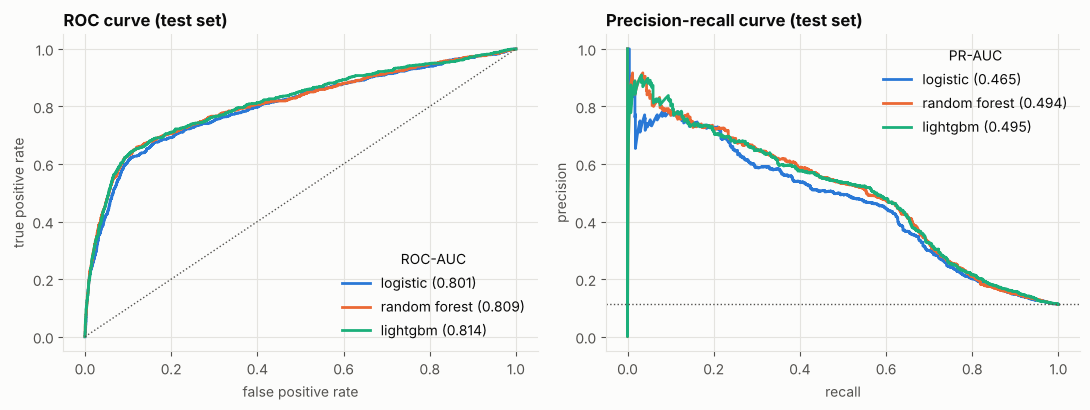

In [6]:
plot_models = ["logistic", "random forest", "lightgbm"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name, color in zip(plot_models, PALETTE):
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    prec, rec, _ = precision_recall_curve(y_test, test_proba[name])
    axes[0].plot(fpr, tpr, color=color, label=f"{name} ({test_df.loc[name, 'roc_auc']:.3f})")
    axes[1].plot(rec, prec, color=color, label=f"{name} ({test_df.loc[name, 'pr_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], color=INK_2, linestyle=":", linewidth=1)
axes[0].set(title="ROC curve (test set)", xlabel="false positive rate", ylabel="true positive rate")
axes[1].axhline(y_test.mean(), color=INK_2, linestyle=":", linewidth=1)
axes[1].set(title="Precision-recall curve (test set)", xlabel="recall", ylabel="precision")
axes[0].legend(title="ROC-AUC", loc="lower right")
axes[1].legend(title="PR-AUC", loc="upper right")
fig.tight_layout()
save(fig, "bank_roc_pr.png");

The dotted line on the PR chart is the positive rate, which is what random guessing gets. All models clear it by a lot at low recall: the first clients they flag are much more likely than average to say yes. Precision falls quickly after that.

## Calibration

If the model says 30%, about 30% of those clients should subscribe. The reliability curve bins predictions and compares the average prediction with the actual rate.

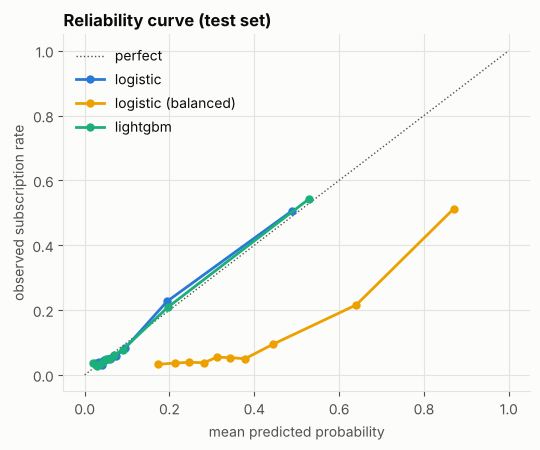

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 4.6))
ax.plot([0, 1], [0, 1], color=INK_2, linestyle=":", linewidth=1, label="perfect")
for name, color in zip(["logistic", "logistic (balanced)", "lightgbm"], [PALETTE[0], PALETTE[3], PALETTE[2]]):
    frac, mean_pred = calibration_curve(y_test, test_proba[name], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", markersize=5, color=color, label=name)
ax.set(title="Reliability curve (test set)", xlabel="mean predicted probability", ylabel="observed subscription rate")
ax.legend(loc="upper left")
fig.tight_layout()

Plain logistic regression and LightGBM sit close to the diagonal, so their outputs can be read as probabilities. The balanced logistic model sits far below it: in its top bin it predicts about 0.87 on average and only about half of those clients subscribe. If I had to use a reweighted model I would recalibrate it on held-out data (Platt or isotonic scaling with `CalibratedClassifierCV`).

## Choosing a threshold from costs

A threshold should come from what mistakes cost, not from 0.5. I do not have the bank's real numbers, so here is a stated assumption that is easy to change:

- Calling a client who says no (false positive) costs **5** units: agent time plus some annoyance.
- Not calling a client who would have said yes (false negative) costs **50** units of lost margin.

With calibrated probabilities, theory says to call whenever p > 5 / (5 + 50), about 0.091. I check that against the data. To avoid tuning on the test set, I pick the threshold from out-of-fold predictions on the training data, then apply it once to the test set.

In [8]:
COST_FP, COST_FN = 5, 50
best_name = test_df["pr_auc"].idxmax()
best_model = models[best_name]
print("model used for the decision:", best_name)

oof = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
t_star = best_threshold(y_train, oof, COST_FP, COST_FN)
print(f"theoretical threshold: {COST_FP / (COST_FP + COST_FN):.3f}")
print(f"cost-minimising threshold on out-of-fold train predictions: {t_star:.2f}")

p_test = test_proba[best_name]
policies = {
    "call nobody": 1.01,
    "default threshold 0.5": 0.5,
    f"cost-based threshold {t_star:.2f}": t_star,
    "call everyone": 0.0,
}
rows = []
for label, t in policies.items():
    pred = (p_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rows.append({"policy": label, "calls": tp + fp, "subscribers reached": tp, "missed": fn,
                 "precision": tp / (tp + fp) if tp + fp else np.nan, "recall": tp / (tp + fn),
                 "total cost": expected_cost(y_test, p_test, t, COST_FP, COST_FN)})
policy_df = pd.DataFrame(rows).set_index("policy")
policy_df

model used for the decision: lightgbm


theoretical threshold: 0.091
cost-minimising threshold on out-of-fold train predictions: 0.11


,calls,subscribers reached,missed,precision,recall,total cost
policy,,,,,,
call nobody,0,0,928,NaN,0.000000,46400.0
default threshold 0.5,407,268,660,0.658477,0.288793,33695.0
cost-based threshold 0.11,1627,615,313,0.377996,0.662716,20710.0
call everyone,8238,928,0,0.112649,1.000000,36550.0


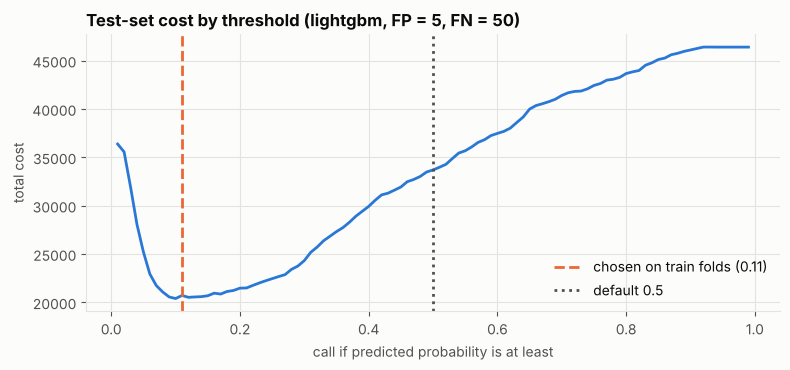

In [9]:
curve = cost_curve(y_test, p_test, COST_FP, COST_FN)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(curve["threshold"], curve["cost"], color=PALETTE[0])
ax.axvline(t_star, color=PALETTE[1], linestyle="--", label=f"chosen on train folds ({t_star:.2f})")
ax.axvline(0.5, color=INK_2, linestyle=":", label="default 0.5")
ax.set(title=f"Test-set cost by threshold ({best_name}, FP = {COST_FP}, FN = {COST_FN})",
       xlabel="call if predicted probability is at least", ylabel="total cost")
ax.legend()
fig.tight_layout()
save(fig, "bank_cost_threshold.png");

The data agree with the theory. The threshold picked on the training folds is 0.11, close to the theoretical 0.091, and the test-set cost curve bottoms out in the same area. On the test set it costs 20,710, against 33,695 at the default 0.5 and 36,550 for calling everyone. It makes 1,627 calls (about a fifth of clients) and reaches 615 of the 928 subscribers, a recall of 66.3%. The 0.5 threshold looks better on precision (65.8%) but misses 660 subscribers, and here a miss costs ten times a wasted call. Change the costs and the threshold moves, which is the point.

## What drives the predictions

### Permutation importance

Shuffle one column in the test set and see how much PR-AUC drops. It works on the raw columns, on any model, and is measured on data the model has not seen. Correlated columns share credit, so a low score for one of a correlated pair does not mean it is useless.

In [10]:
perm = permutation_importance(best_model, X_test, y_test, scoring="average_precision",
                              n_repeats=10, random_state=SEED, n_jobs=1)
imp = (pd.DataFrame({"feature": X_test.columns, "drop_in_pr_auc": perm.importances_mean, "sd": perm.importances_std})
       .sort_values("drop_in_pr_auc", ascending=False, ignore_index=True))
imp

,feature,drop_in_pr_auc,sd
0,nr_employed,0.078668,0.006778
1,euribor3m,0.039164,0.004401
2,month,0.029004,0.001873
3,previously_contacted,0.026581,0.002665
4,contact,0.025636,0.002009
5,day_of_week,0.016911,0.003943
6,poutcome,0.014502,0.002105
7,campaign,0.014481,0.003750
8,cons_conf_idx,0.009722,0.001826
9,emp_var_rate,0.004778,0.002264


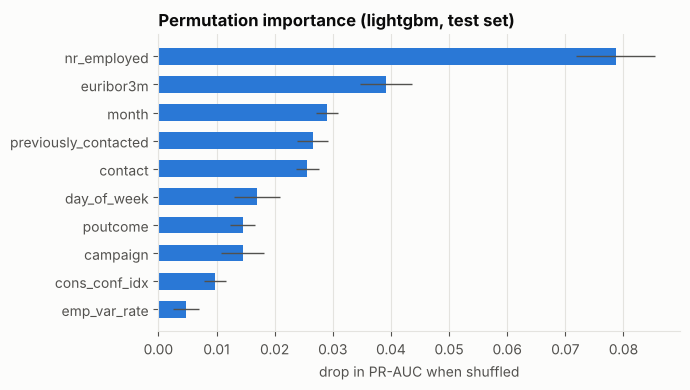

In [11]:
top = imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top["feature"], top["drop_in_pr_auc"], xerr=top["sd"], color=PALETTE[0], height=0.6,
        error_kw={"ecolor": INK_2, "elinewidth": 1})
ax.set(title=f"Permutation importance ({best_name}, test set)", xlabel="drop in PR-AUC when shuffled")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "bank_permutation_importance.png");

### SHAP values for the LightGBM model

SHAP splits each single prediction into per-feature contributions. The mean absolute SHAP value gives a global ranking, and the sign tells me direction. I compute it on a sample of 2,000 test rows to keep it fast.

In [12]:
lgb_pipe = fitted["lightgbm"]
X_sample = X_test.sample(2000, random_state=SEED)
X_enc = pd.DataFrame(lgb_pipe.named_steps["pre"].transform(X_sample),
                     columns=lgb_pipe.named_steps["pre"].get_feature_names_out(), index=X_sample.index)
explainer = shap.TreeExplainer(lgb_pipe.named_steps["clf"])
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)  # shap notes a change in its LightGBM output format
    sv = explainer.shap_values(X_enc)
sv = sv[1] if isinstance(sv, list) else sv
shap_imp = pd.Series(np.abs(sv).mean(axis=0), index=X_enc.columns).sort_values(ascending=False)
shap_imp.head(10).to_frame("mean |SHAP| (log-odds)")

,mean |SHAP| (log-odds)
nr_employed,0.288295
euribor3m,0.232568
contact,0.183180
emp_var_rate,0.102572
campaign,0.098960
cons_conf_idx,0.094328
age,0.084958
day_of_week,0.081991
month,0.061098
poutcome,0.057412


In [13]:
for col in ["nr_employed", "euribor3m"]:
    r = np.corrcoef(X_enc[col], sv[:, X_enc.columns.get_loc(col)])[0, 1]
    print(f"correlation between {col} and its SHAP value: {r:.3f}")

correlation between nr_employed and its SHAP value: -0.648
correlation between euribor3m and its SHAP value: -0.717


Both methods agree that two macro columns dominate: `nr_employed` (number employed in the economy) and `euribor3m` (the 3-month interest rate). SHAP shows both push the probability down as they rise (correlations of -0.648 and -0.717 with their SHAP values). In plain terms, clients said yes far more often later in the campaign, after rates and employment had fallen. That is a real pattern, but it is about when the call happened, not who the client is. Of the client-level features, contact type, previous contact and the number of calls this campaign matter most. Job, marital status and education add almost nothing once the rest is known.

## A harder test: train on earlier calls, predict later ones

The file is in time order, so I can train on the first 80% of rows and test on the last 20%. This is closer to how the model would be used: built on past campaigns, applied to the next one.

In [14]:
cut = int(len(X) * 0.8)
X_early, X_late, y_early, y_late = X.iloc[:cut], X.iloc[cut:], y.iloc[:cut], y.iloc[cut:]
print(f"early rows: positive rate {y_early.mean():.4f}   late rows: positive rate {y_late.mean():.4f}")
time_rows = {}
for name in ["logistic", "lightgbm"]:
    m = models[name].fit(X_early, y_early)
    p = m.predict_proba(X_late)[:, 1]
    time_rows[name] = {"roc_auc": roc_auc_score(y_late, p), "pr_auc": average_precision_score(y_late, p),
                       "brier": brier_score_loss(y_late, p), "mean_predicted": p.mean(), "actual_rate": y_late.mean()}
time_df = pd.DataFrame(time_rows).T
time_df

early rows: positive rate 0.0637   late rows: positive rate 0.3083


,roc_auc,pr_auc,brier,mean_predicted,actual_rate
logistic,0.748401,0.527045,0.190509,0.256369,0.308327
lightgbm,0.658348,0.444842,0.249813,0.092790,0.308327


This is a very different picture. The later 20% of calls converted at 30.83%, against 6.37% for the earlier ones, so the world changed under the model. Logistic regression holds up better (ROC-AUC 0.748) than LightGBM (0.658). Trees cannot extrapolate: the later period has interest rates and employment outside the range seen in training, and a tree treats those values like the most extreme one it has seen. LightGBM's average predicted probability is 0.093 against an actual rate of 0.308, so its probabilities are badly off as well. (PR-AUC is not comparable with the earlier table, because its baseline is the positive rate, which is now much higher.)

So the random-split numbers above are fine for comparing models within one period, but they overstate how well any of these would do on the next campaign. Before using this for real I would validate on time, retrain often, and monitor the macro features for drift.

In [15]:
(RESULTS / "classification.json").write_text(json.dumps({
    "n_train": len(X_train), "n_test": len(X_test), "positive_rate": float(y.mean()),
    "cv_5fold": cv_df.to_dict(orient="index"),
    "test": test_df.to_dict(orient="index"),
    "decision_model": best_name,
    "cost_fp": COST_FP, "cost_fn": COST_FN, "threshold": t_star,
    "policies": policy_df.reset_index().to_dict(orient="records"),
    "top_permutation_features": imp.head(5)["feature"].tolist(),
    "time_ordered_check": time_df.to_dict(orient="index"),
}, indent=2, default=float))
print("saved results/classification.json")

saved results/classification.json
